In [1]:
import torch
import torch_geometric
print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("✅ Environment is correct!")

PyTorch: 2.13.0+cpu
PyG: 2.8.0.post1
✅ Environment is correct!


In [3]:
import pandas as pd
import numpy as np
import torch
from torch_geometric.data import Data
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import warnings
import os
warnings.filterwarnings('ignore')

print("PyTorch:", torch.__version__)
ibm = pd.read_csv('IBM Transaction Dataset/HI-Small_Trans.csv')
print("IBM loaded:", ibm.shape)
print("Columns:", ibm.columns.tolist())

PyTorch: 2.13.0+cpu
IBM loaded: (5078345, 11)
Columns: ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


In [4]:
ibm['sender_id']   = ibm['From Bank'].astype(str) + '_' + ibm['Account'].astype(str)
ibm['receiver_id'] = ibm['To Bank'].astype(str)   + '_' + ibm['Account.1'].astype(str)

all_accounts   = pd.concat([ibm['sender_id'], ibm['receiver_id']]).unique()
account_to_idx = {acc: idx for idx, acc in enumerate(all_accounts)}

print(f"Total unique accounts (nodes): {len(all_accounts):,}")
print(f"Total transactions (edges):    {len(ibm):,}")

Total unique accounts (nodes): 515,088
Total transactions (edges):    5,078,345


In [5]:
print("Building behavioral features...")

sent_stats = ibm.groupby('sender_id').agg(
    total_sent       = ('Amount Paid', 'sum'),
    num_sent         = ('Amount Paid', 'count'),
    unique_receivers = ('receiver_id', 'nunique')
).reset_index().rename(columns={'sender_id':'account'})

recv_stats = ibm.groupby('receiver_id').agg(
    total_received = ('Amount Received', 'sum'),
    num_received   = ('Amount Received', 'count'),
    unique_senders = ('sender_id', 'nunique')
).reset_index().rename(columns={'receiver_id':'account'})

all_acc_df = pd.DataFrame({'account': all_accounts})
all_acc_df = all_acc_df.merge(sent_stats, on='account', how='left')
all_acc_df = all_acc_df.merge(recv_stats, on='account', how='left')
all_acc_df = all_acc_df.fillna(0)

all_acc_df['avg_sent']     = all_acc_df['total_sent']     / all_acc_df['num_sent'].replace(0,1)
all_acc_df['avg_received'] = all_acc_df['total_received'] / all_acc_df['num_received'].replace(0,1)
all_acc_df['net_flow']     = all_acc_df['total_received'] - all_acc_df['total_sent']

print(f"Behavioral features done: {all_acc_df.shape}")
print("✅ Done!")

Building behavioral features...
Behavioral features done: (515088, 10)
✅ Done!


In [6]:
print("Building NetworkX graph for graph features...")
print("(This will take 3-5 minutes — please wait)")

G = nx.DiGraph()

# Edges add karo in batches
edges = list(zip(ibm['sender_id'], ibm['receiver_id']))
G.add_edges_from(edges)

print(f"Graph built: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")

# Feature 1: In-degree (kitne log paisa bhejte hain is account ko)
print("Computing in-degree...")
in_degree  = dict(G.in_degree())

# Feature 2: Out-degree (ye account kitne logo ko paisa bhejta hai)
print("Computing out-degree...")
out_degree = dict(G.out_degree())

# Feature 3: PageRank (suspicious accounts ka score high hota hai)
print("Computing PageRank... (2-3 minutes)")
try:
    pagerank = nx.pagerank(G, max_iter=200, tol=1e-4)
    print("PageRank done!")
except:
    print("PageRank failed, using degree as proxy")
    pagerank = {n: G.in_degree(n) / max(G.number_of_nodes(), 1) for n in G.nodes()}

# Feature 4: Clustering coefficient
print("Computing clustering coefficient...")
G_un = G.to_undirected()
try:
    clustering = nx.clustering(G_un)
    print("Clustering done!")
except:
    clustering = {n: 0 for n in G_un.nodes()}

# Add to dataframe
all_acc_df['in_degree']  = all_acc_df['account'].map(in_degree).fillna(0)
all_acc_df['out_degree'] = all_acc_df['account'].map(out_degree).fillna(0)
all_acc_df['pagerank']   = all_acc_df['account'].map(pagerank).fillna(0)
all_acc_df['clustering'] = all_acc_df['account'].map(clustering).fillna(0)

print(f"\n✅ Graph features added!")
print(f"Total features now: 13")
print(all_acc_df[['account','in_degree','out_degree','pagerank','clustering']].head(3))

Building NetworkX graph for graph features...
(This will take 3-5 minutes — please wait)
Graph built: 515,088 nodes, 1,015,736 edges
Computing in-degree...
Computing out-degree...
Computing PageRank... (2-3 minutes)
PageRank done!
Computing clustering coefficient...
Clustering done!

✅ Graph features added!
Total features now: 13
          account  in_degree  out_degree      pagerank  clustering
0    10_8000EBD30         13           2  5.189107e-06    0.012821
1  3208_8000F4580          0           2  3.491647e-07    0.000000
2  3209_8000F4670          1           1  1.999368e-06    0.000000


In [9]:
fraud_sent = ibm.groupby('sender_id')['Is Laundering'].sum().reset_index()\
    .rename(columns={'sender_id':'account','Is Laundering':'fraud_sent'})
fraud_recv = ibm.groupby('receiver_id')['Is Laundering'].sum().reset_index()\
    .rename(columns={'receiver_id':'account','Is Laundering':'fraud_received'})

label_df = pd.DataFrame({'account': all_accounts})
label_df = label_df.merge(fraud_sent, on='account', how='left')
label_df = label_df.merge(fraud_recv, on='account', how='left')
label_df = label_df.fillna(0)
label_df['total_fraud'] = label_df['fraud_sent'] + label_df['fraud_received']

y = torch.tensor(
    (label_df['total_fraud'] > 0).astype(int).values,
    dtype=torch.long
)

print(f"Fraud nodes:  {y.sum().item():,}")
print(f"Legit nodes:  {(y==0).sum().item():,}")
print(f"Fraud ratio:  {y.float().mean().item()*100:.2f}%")
print("✅ Labels ready!")

Fraud nodes:  6,357
Legit nodes:  508,731
Fraud ratio:  1.23%
✅ Labels ready!


In [10]:
feature_cols = [
    'total_sent', 'total_received',
    'num_sent', 'num_received',
    'avg_sent', 'avg_received',
    'unique_receivers', 'unique_senders',
    'net_flow',
    'in_degree', 'out_degree',
    'pagerank', 'clustering'
]

x = torch.tensor(all_acc_df[feature_cols].values, dtype=torch.float)

# Normalize
scaler   = StandardScaler()
x_scaled = torch.tensor(scaler.fit_transform(x.numpy()), dtype=torch.float)

print(f"Feature matrix: {x_scaled.shape}")
print(f"Features: {feature_cols}")
print("✅ Features normalized!")

Feature matrix: torch.Size([515088, 13])
Features: ['total_sent', 'total_received', 'num_sent', 'num_received', 'avg_sent', 'avg_received', 'unique_receivers', 'unique_senders', 'net_flow', 'in_degree', 'out_degree', 'pagerank', 'clustering']
✅ Features normalized!


In [11]:
print("Building edges...")
src_nodes  = ibm['sender_id'].map(account_to_idx).values.tolist()
dst_nodes  = ibm['receiver_id'].map(account_to_idx).values.tolist()
edge_index = torch.tensor([src_nodes, dst_nodes], dtype=torch.long)
edge_attr  = torch.tensor(
    ibm['Amount Paid'].fillna(0).values, dtype=torch.float
).unsqueeze(1)

print(f"Edge index: {edge_index.shape}")
print(f"Edge attr:  {edge_attr.shape}")
print("✅ Edges ready!")

Building edges...
Edge index: torch.Size([2, 5078345])
Edge attr:  torch.Size([5078345, 1])
✅ Edges ready!


In [12]:
num_nodes  = x_scaled.shape[0]
indices    = torch.randperm(num_nodes)
train_end  = int(0.70 * num_nodes)
val_end    = int(0.85 * num_nodes)

train_mask = torch.zeros(num_nodes, dtype=torch.bool)
val_mask   = torch.zeros(num_nodes, dtype=torch.bool)
test_mask  = torch.zeros(num_nodes, dtype=torch.bool)

train_mask[indices[:train_end]]      = True
val_mask[indices[train_end:val_end]] = True
test_mask[indices[val_end:]]         = True

print(f"Total nodes:  {num_nodes:,}")
print(f"Train:        {train_mask.sum().item():,}")
print(f"Val:          {val_mask.sum().item():,}")
print(f"Test:         {test_mask.sum().item():,}")

Total nodes:  515,088
Train:        360,561
Val:          77,263
Test:         77,264


In [13]:
data = Data(
    x          = x_scaled,
    edge_index = edge_index,
    edge_attr  = edge_attr,
    y          = y,
    train_mask = train_mask,
    val_mask   = val_mask,
    test_mask  = test_mask
)

print("="*45)
print("   FINAL GRAPH SUMMARY")
print("="*45)
print(data)
print(f"\nNodes:           {data.num_nodes:,}")
print(f"Edges:           {data.num_edges:,}")
print(f"Features:        {data.num_node_features}")
print(f"Fraud nodes:     {data.y.sum().item():,}")

# Save
os.makedirs('outputs', exist_ok=True)
torch.save(data, 'outputs/ibm_graph.pt')

import pickle, joblib
with open('outputs/account_to_idx.pkl', 'wb') as f:
    pickle.dump(account_to_idx, f)
joblib.dump(scaler, 'outputs/scaler.pkl')

print("\n✅ Graph saved to outputs/ibm_graph.pt")
print("🎉 Graph construction complete!")
print("   13 features: 9 behavioral + 4 graph-specific")

   FINAL GRAPH SUMMARY
Data(x=[515088, 13], edge_index=[2, 5078345], edge_attr=[5078345, 1], y=[515088], train_mask=[515088], val_mask=[515088], test_mask=[515088])

Nodes:           515,088
Edges:           5,078,345
Features:        13
Fraud nodes:     6,357

✅ Graph saved to outputs/ibm_graph.pt
🎉 Graph construction complete!
   13 features: 9 behavioral + 4 graph-specific


Building fraud subgraph visualization...


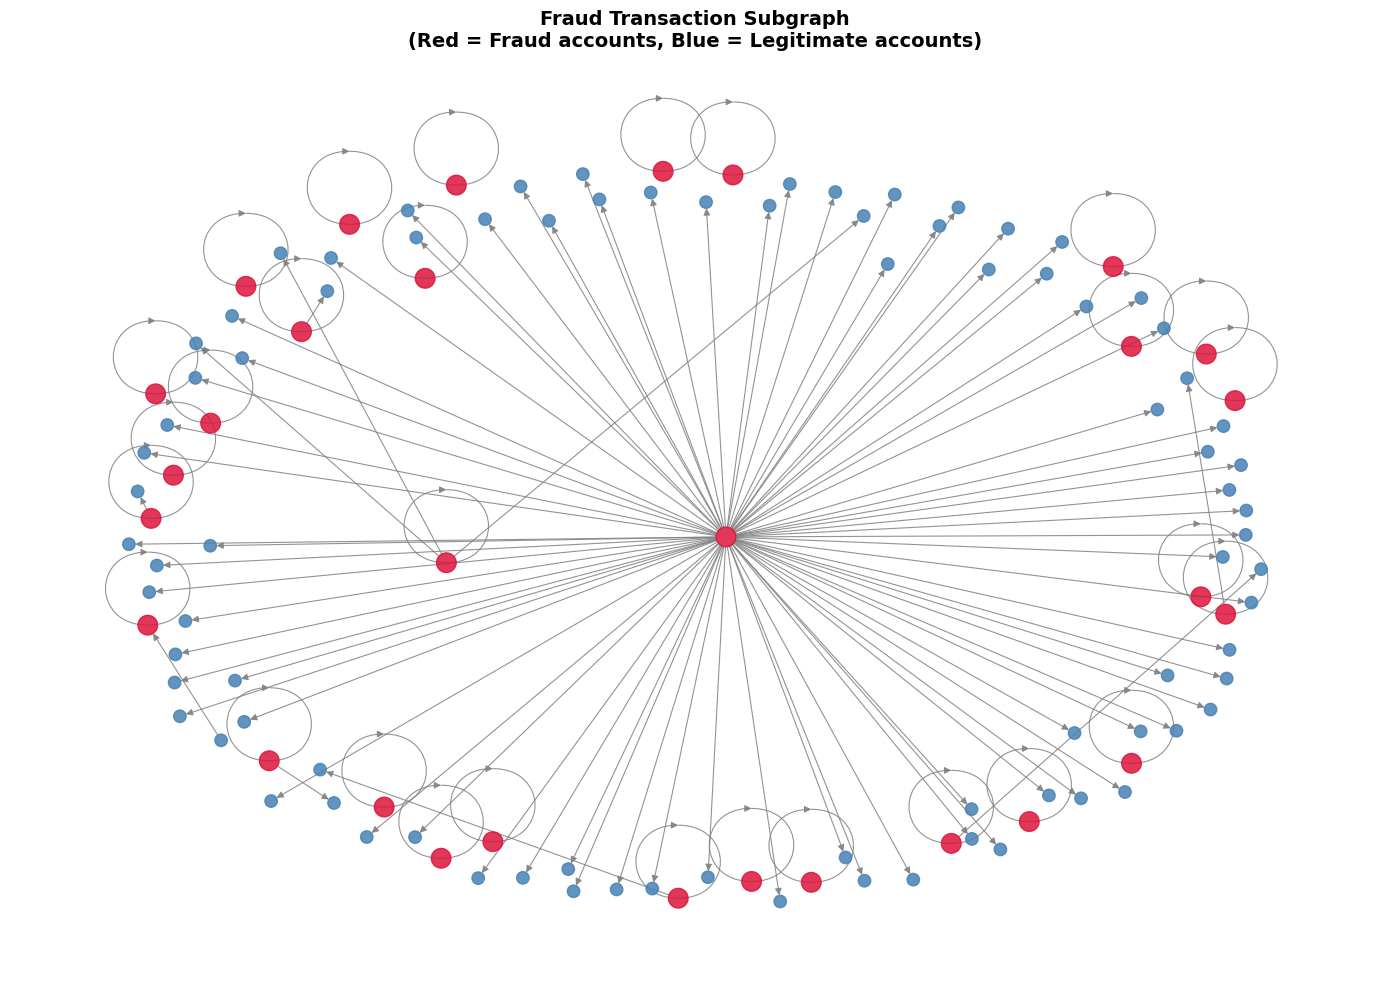

✅ Basic subgraph saved!


In [15]:
print("Building fraud subgraph visualization...")

# Sirf fraud nodes aur unke direct neighbors lo
fraud_node_indices = (y == 1).nonzero(as_tuple=True)[0][:30]
fraud_set = set(fraud_node_indices.numpy())

edge_src = edge_index[0].numpy()
edge_dst = edge_index[1].numpy()

G_small = nx.DiGraph()
for s, d in zip(edge_src[:10000], edge_dst[:10000]):
    if s in fraud_set or d in fraud_set:
        G_small.add_edge(s, d)

node_colors = ['crimson' if n in fraud_set else 'steelblue' 
               for n in G_small.nodes()]
node_sizes  = [200 if n in fraud_set else 80 
               for n in G_small.nodes()]

plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G_small, seed=42, k=0.8)
nx.draw_networkx(
    G_small, pos,
    node_color=node_colors,
    node_size=node_sizes,
    arrows=True,
    edge_color='gray',
    alpha=0.85,
    with_labels=False,
    width=0.8
)
plt.title('Fraud Transaction Subgraph\n(Red = Fraud accounts, Blue = Legitimate accounts)',
          fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig('outputs/fraud_subgraph_basic.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Basic subgraph saved!")

In [18]:
from pyvis.network import Network

print("Building interactive visualization...")

fraud_nodes_viz = (y == 1).nonzero(as_tuple=True)[0][:50]
fraud_set_viz   = set(fraud_nodes_viz.numpy().tolist())

net = Network(
    height="600px", width="100%",
    bgcolor="#1a1a2e", font_color="white",
    notebook=True, cdn_resources='in_line'
)

net.set_options("""
{
  "nodes": {"borderWidth": 2, "shadow": true},
  "edges": {
    "color": {"color": "rgba(255,255,255,0.3)"},
    "smooth": {"type": "continuous"},
    "arrows": {"to": {"enabled": true, "scaleFactor": 0.5}}
  },
  "physics": {
    "forceAtlas2Based": {
      "gravitationalConstant": -50,
      "springLength": 100
    },
    "solver": "forceAtlas2Based",
    "stabilization": {"iterations": 100}
  }
}
""")

added_nodes = set()
edge_count  = 0

for s, d in zip(edge_src[:20000], edge_dst[:20000]):
    # Fix: integer ko string mein convert karo
    s_id = str(int(s))
    d_id = str(int(d))
    s_int = int(s)
    d_int = int(d)

    if s_int in fraud_set_viz or d_int in fraud_set_viz:
        if s_id not in added_nodes:
            color = "#E94560" if s_int in fraud_set_viz else "#4A90D9"
            size  = 20 if s_int in fraud_set_viz else 10
            title = f"FRAUD Node {s_id}" if s_int in fraud_set_viz else f"Node {s_id}"
            net.add_node(s_id, color=color, size=size, title=title, label="")
            added_nodes.add(s_id)

        if d_id not in added_nodes:
            color = "#E94560" if d_int in fraud_set_viz else "#4A90D9"
            size  = 20 if d_int in fraud_set_viz else 10
            title = f"FRAUD Node {d_id}" if d_int in fraud_set_viz else f"Node {d_id}"
            net.add_node(d_id, color=color, size=size, title=title, label="")
            added_nodes.add(d_id)

        net.add_edge(s_id, d_id)
        edge_count += 1
        if edge_count > 300:
            break

# net.save_graph('outputs/fraud_network_interactive.html')
import os

os.makedirs("outputs", exist_ok=True)

html = net.generate_html()

with open(
    "outputs/fraud_network_interactive.html",
    "w",
    encoding="utf-8"
) as f:
    f.write(html)
    
print(f"✅ Interactive visualization saved!")
print(f"   Nodes: {len(added_nodes)}")
print(f"   Edges: {edge_count}")
print("   Open 'outputs/fraud_network_interactive.html' in browser!")

Building interactive visualization...
✅ Interactive visualization saved!
   Nodes: 164
   Edges: 301
   Open 'outputs/fraud_network_interactive.html' in browser!


In [19]:
import os

path = os.path.abspath("outputs/fraud_network_interactive.html")

print("File location:")
print(path)

print("\nFile exists:", os.path.exists(path))

if os.path.exists(path):
    print("File size:", os.path.getsize(path), "bytes")

File location:
C:\Users\divya\OneDrive\Desktop\fraud_gnn\outputs\fraud_network_interactive.html

File exists: True
File size: 730442 bytes


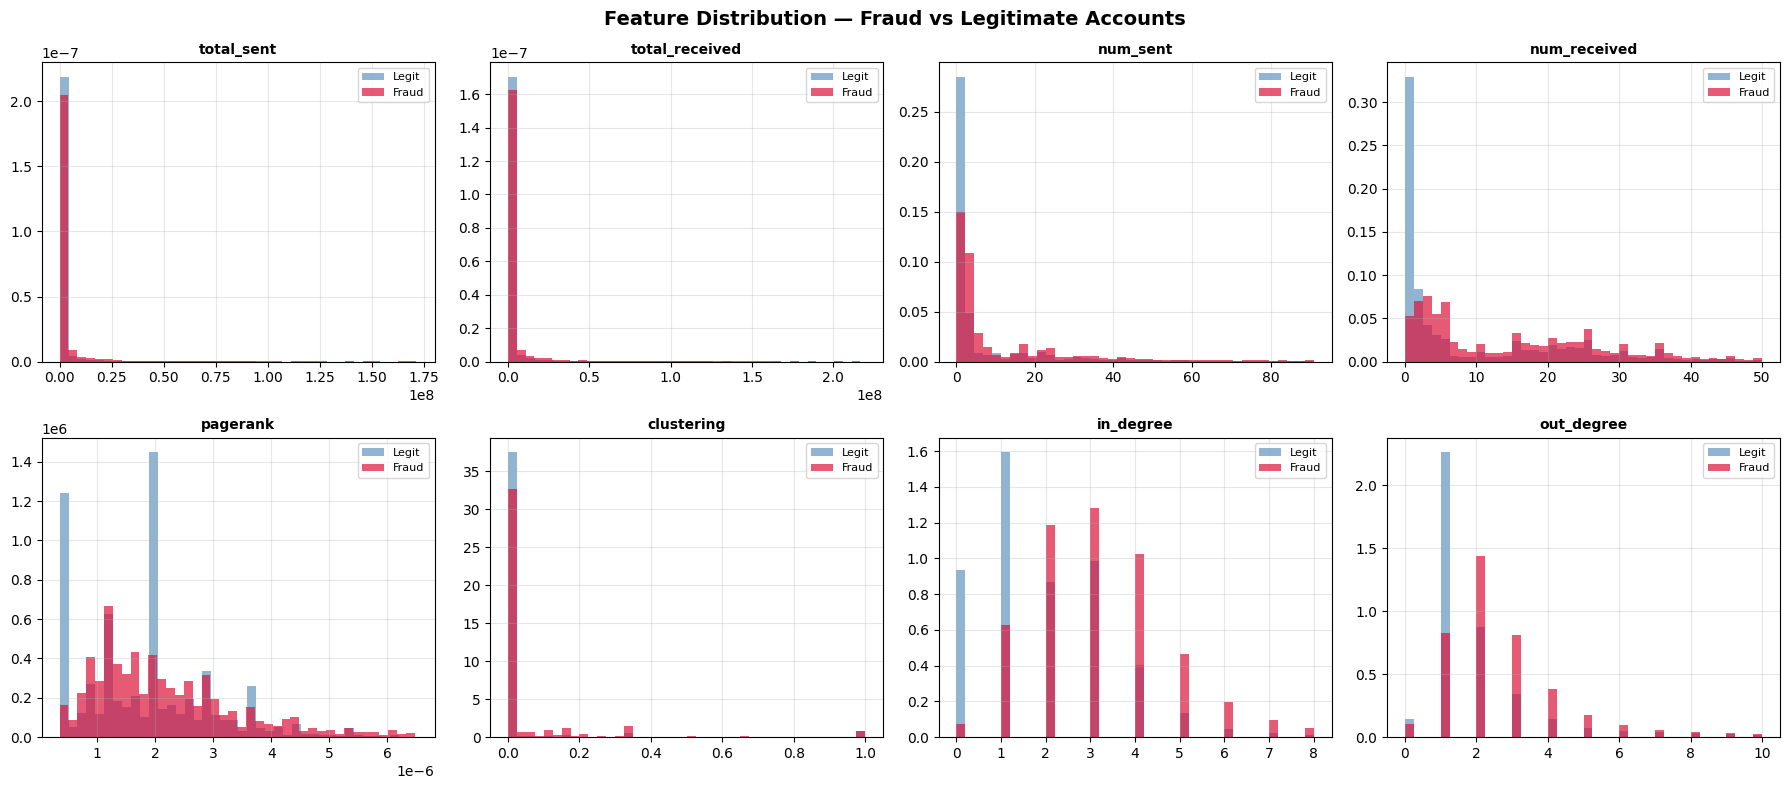

✅ Feature distribution plot saved!


In [20]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Feature Distribution — Fraud vs Legitimate Accounts',
             fontsize=14, fontweight='bold')

features_to_plot = [
    'total_sent', 'total_received', 'num_sent', 'num_received',
    'pagerank', 'clustering', 'in_degree', 'out_degree'
]

fraud_mask_np = y.numpy() == 1
legit_mask_np = y.numpy() == 0

for ax, feat in zip(axes.flatten(), features_to_plot):
    feat_idx = feature_cols.index(feat)
    fraud_vals = x.numpy()[fraud_mask_np, feat_idx]
    legit_vals = x.numpy()[legit_mask_np, feat_idx]

    # Clip outliers for better visualization
    p99 = np.percentile(np.concatenate([fraud_vals, legit_vals]), 99)

    ax.hist(legit_vals[legit_vals <= p99], bins=40,
            color='steelblue', alpha=0.6, label='Legit', density=True)
    ax.hist(fraud_vals[fraud_vals <= p99], bins=40,
            color='crimson', alpha=0.7, label='Fraud', density=True)
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Feature distribution plot saved!")

   GRAPH STATISTICS SUMMARY

Graph Properties:
  Total Nodes:          105
  Total Edges:          102
  Avg Degree:           1.94
  Max Degree:           42

Fraud vs Legit Comparison:
  Avg degree (Fraud):   nan
  Avg degree (Legit):   nan
  Avg PageRank (Fraud): 0.000003
  Avg PageRank (Legit): 0.000002


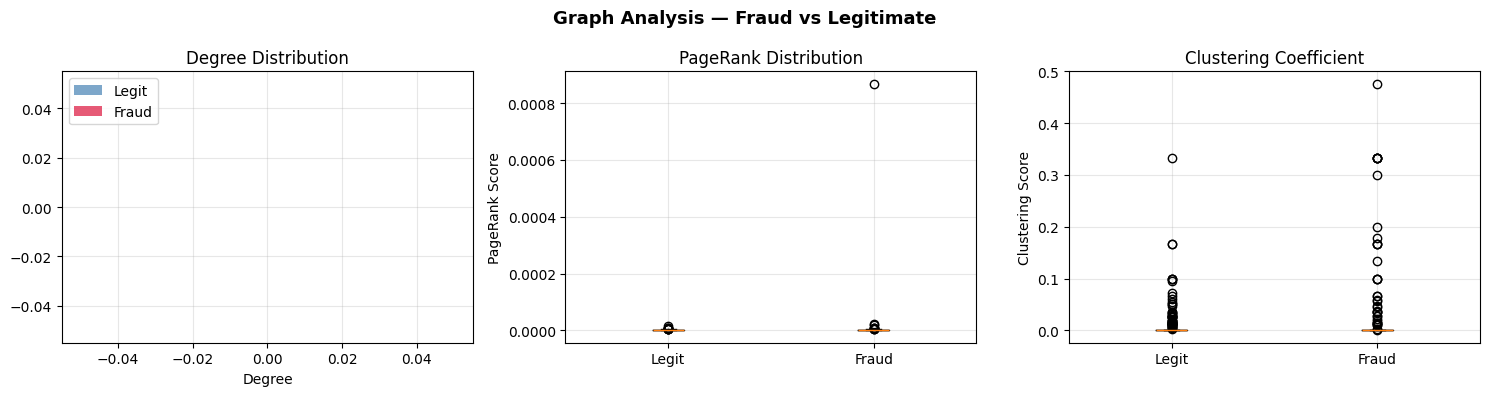


✅ All visualizations saved!

Files created:
  outputs/fraud_subgraph_basic.png      ← Static graph
  outputs/fraud_network_interactive.html ← Interactive graph
  outputs/feature_distributions.png     ← Feature analysis
  outputs/graph_analysis.png            ← Graph statistics


In [21]:
print("="*55)
print("   GRAPH STATISTICS SUMMARY")
print("="*55)

# Degree distribution
degrees = [d for n, d in G.degree()]
fraud_accounts = label_df[label_df['total_fraud'] > 0]['account'].tolist()

fraud_degrees = [G.degree(a) for a in fraud_accounts if a in G]
legit_accounts = label_df[label_df['total_fraud'] == 0]['account'].tolist()
legit_degrees  = [G.degree(a) for a in legit_accounts[:1000] if a in G]

print(f"\nGraph Properties:")
print(f"  Total Nodes:          {G.number_of_nodes():,}")
print(f"  Total Edges:          {G.number_of_edges():,}")
print(f"  Avg Degree:           {np.mean(degrees):.2f}")
print(f"  Max Degree:           {max(degrees):,}")

print(f"\nFraud vs Legit Comparison:")
print(f"  Avg degree (Fraud):   {np.mean(fraud_degrees):.2f}")
print(f"  Avg degree (Legit):   {np.mean(legit_degrees):.2f}")

avg_pr_fraud = np.mean([pagerank.get(a, 0) for a in fraud_accounts])
avg_pr_legit = np.mean([pagerank.get(a, 0) for a in legit_accounts[:1000]])
print(f"  Avg PageRank (Fraud): {avg_pr_fraud:.6f}")
print(f"  Avg PageRank (Legit): {avg_pr_legit:.6f}")

# Plot degree distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Graph Analysis — Fraud vs Legitimate', fontsize=13, fontweight='bold')

axes[0].hist(legit_degrees, bins=30, color='steelblue',
             alpha=0.7, label='Legit', density=True)
axes[0].hist(fraud_degrees, bins=30, color='crimson',
             alpha=0.7, label='Fraud', density=True)
axes[0].set_title('Degree Distribution')
axes[0].set_xlabel('Degree')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# PageRank comparison
pr_fraud = [pagerank.get(a, 0) for a in fraud_accounts[:200]]
pr_legit = [pagerank.get(a, 0) for a in legit_accounts[:200]]
axes[1].boxplot([pr_legit, pr_fraud], labels=['Legit', 'Fraud'])
axes[1].set_title('PageRank Distribution')
axes[1].set_ylabel('PageRank Score')
axes[1].grid(True, alpha=0.3)

# Clustering comparison
cl_fraud = [clustering.get(a, 0) for a in fraud_accounts[:200]]
cl_legit = [clustering.get(a, 0) for a in legit_accounts[:200]]
axes[2].boxplot([cl_legit, cl_fraud], labels=['Legit', 'Fraud'])
axes[2].set_title('Clustering Coefficient')
axes[2].set_ylabel('Clustering Score')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('outputs/graph_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ All visualizations saved!")
print("\nFiles created:")
print("  outputs/fraud_subgraph_basic.png      ← Static graph")
print("  outputs/fraud_network_interactive.html ← Interactive graph")
print("  outputs/feature_distributions.png     ← Feature analysis")
print("  outputs/graph_analysis.png            ← Graph statistics")